<a href="https://colab.research.google.com/github/piyushgotefode/Testing/blob/main/Air_Quality_prediction_using_ml.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_path = '/content/city_day[1].csv'

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())


Dataset loaded successfully!
Dataset shape: (29531, 16)


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [ ]:
print("Rows and Columns:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDataset Information:")
df.info()


Rows and Columns: (29531, 16)

Column Names:
['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket']

Missing Values:
City              0
Date              0
PM2.5          4598
PM10          11140
NO             3582
NO2            3585
NOx            4185
NH3           10328
CO             2059
SO2            3854
O3             4022
Benzene        5623
Toluene        8041
Xylene        18109
AQI            4681
AQI_Bucket     4681
dtype: int64

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        29531 non-null  object 
 1   Date        29531 non-null  object 
 2   PM2.5       24933 non-null  float64
 3   PM10        18391 non-null  float64
 4   NO          25949 non-null  float64
 5   NO2         25946 non-null  float64
 6   NOx     

In [ ]:

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Required input features
features = [
    'PM2.5', 'PM10', 'NO2', 'NH3',
    'CO', 'SO2', 'O3', 'NOx'
]

target = 'AQI'

# Check required columns
required_columns = features + [target]
missing_columns = [col for col in required_columns if col not in df.columns]

if missing_columns:
    raise ValueError(f"Columns not found: {missing_columns}")

# Convert selected columns to numeric
for col in required_columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Remove rows where AQI is missing
df = df.dropna(subset=[target]).copy()

# Replace invalid negative pollutant readings with NaN
for col in features:
    df.loc[df[col] < 0, col] = np.nan

print("Cleaning completed!")
print("Cleaned dataset shape:", df.shape)
display(df[features + [target]].head())


Cleaning completed!
Cleaned dataset shape: (24850, 16)


,PM2.5,PM10,NO2,NH3,CO,SO2,O3,NOx,AQI
28,83.13,NaN,28.71,NaN,6.93,49.52,59.76,33.72,209.0
29,79.84,NaN,28.68,NaN,13.85,48.49,97.07,41.08,328.0
30,94.52,NaN,32.66,NaN,24.39,67.39,111.33,52.61,514.0
31,135.99,NaN,42.08,NaN,43.48,75.23,102.70,84.57,782.0
32,178.33,NaN,35.31,NaN,54.56,55.04,107.38,72.80,914.0


In [ ]:

X = df[features]
y = df[target]

print("Input features:", X.shape)
print("Target values:", y.shape)

print("\nFeatures used:")
for feature in features:
    print("-", feature)


Input features: (24850, 8)
Target values: (24850,)

Features used:
- PM2.5
- PM10
- NO2
- NH3
- CO
- SO2
- O3
- NOx


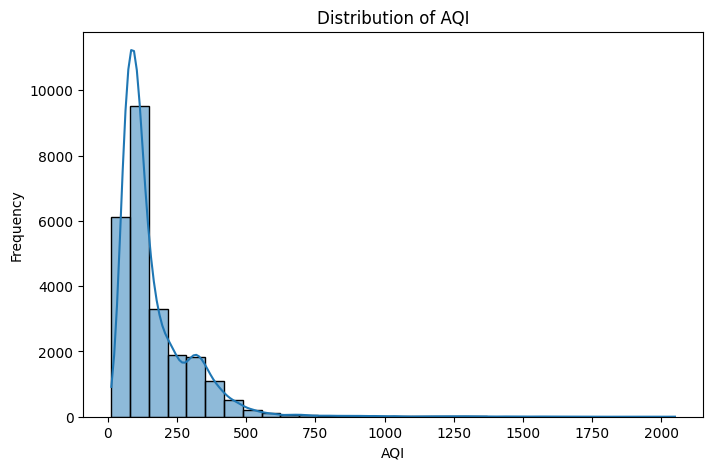

In [ ]:

# Graph 1: AQI distribution
plt.figure(figsize=(8, 5))
sns.histplot(df['AQI'], bins=30, kde=True)
plt.title('Distribution of AQI')
plt.xlabel('AQI')
plt.ylabel('Frequency')
plt.show()



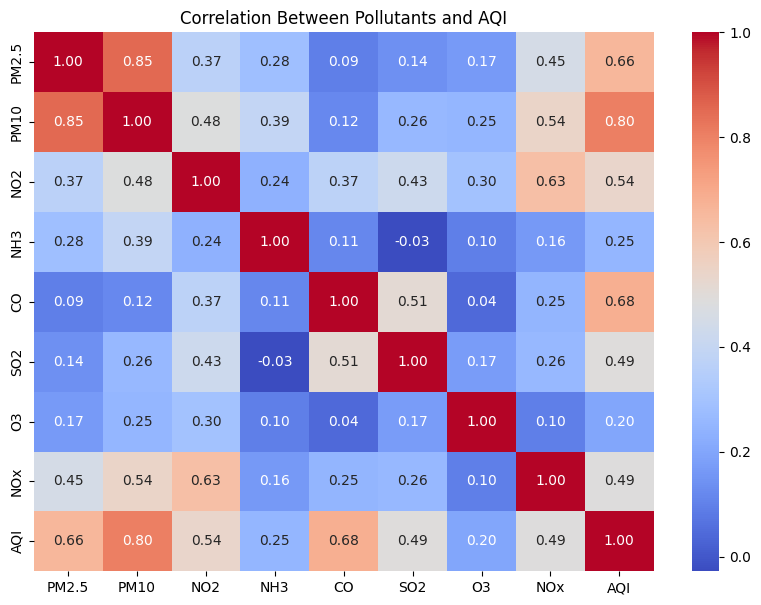

In [ ]:
# Graph 2: Correlation heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(
    df[features + [target]].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title('Correlation Between Pollutants and AQI')
plt.show()

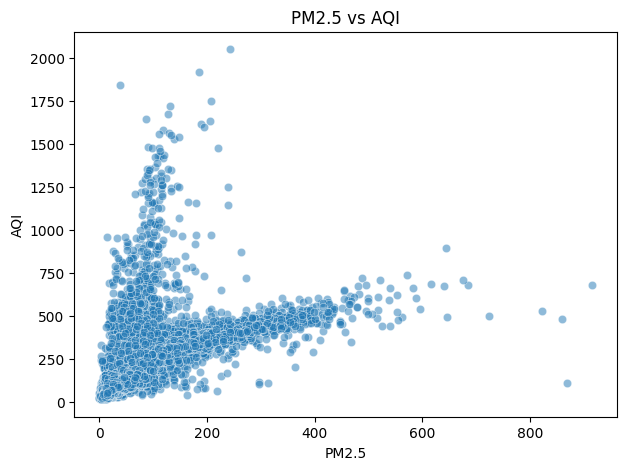

In [ ]:
# Graph 3: PM2.5 vs AQI
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x='PM2.5', y='AQI', alpha=0.5)
plt.title('PM2.5 vs AQI')
plt.show()


In [ ]:
from sklearn.model_selection import train_test_split

# Ensure X and y are defined from the dataframe in case the previous cell wasn't run
if 'X' not in globals() or 'y' not in globals():
    X = df[features]
    y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 19880
Testing rows: 4970


In [ ]:

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.ensemble import GradientBoostingRegressor

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score

models = {
    'Linear Regression': LinearRegression(),

    'Decision Tree': DecisionTreeRegressor(
        random_state=42,
        max_depth=12
    ),

    'Random Forest': RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    'KNN': KNeighborsRegressor(
        n_neighbors=5
    ),

    'SVR': SVR(
        kernel='rbf'
    ),

    'Gradient Boosting': GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        random_state=42
    )
}

results = []
trained_models = {}
predictions = {}

for name, model in models.items():

    pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results.append({
        'Algorithm': name,
        'MAE': mae,
        'RMSE': rmse,
        'R2 Score (%)': r2 * 100
    })

    trained_models[name] = pipeline
    predictions[name] = y_pred

    print(f"{name} trained successfully!")

print("\nAll 6 algorithms trained!")


Linear Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!
KNN trained successfully!
SVR trained successfully!
Gradient Boosting trained successfully!

All 6 algorithms trained!


In [ ]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='RMSE',
    ascending=True
).reset_index(drop=True)

display(results_df.round(3))

best_model_name = results_df.loc[0, 'Algorithm']

print("Best model based on lowest RMSE:", best_model_name)


,Algorithm,MAE,RMSE,R2 Score (%)
0,Random Forest,21.031,40.525,91.031
1,Gradient Boosting,23.627,43.650,89.595
2,KNN,23.868,47.455,87.701
3,Decision Tree,24.778,50.713,85.955
4,Linear Regression,31.116,59.473,80.684
5,SVR,31.740,76.229,68.266


Best model based on lowest RMSE: Random Forest


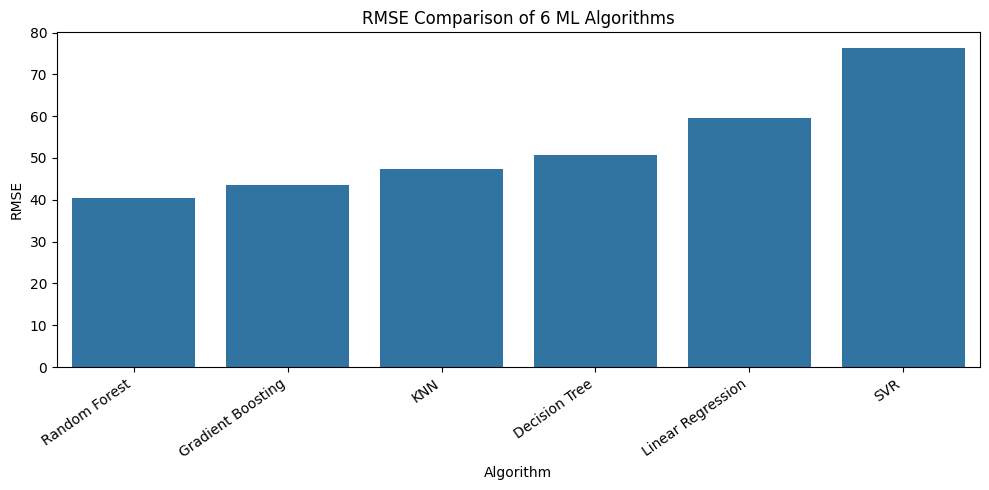

In [ ]:
# Compare RMSE
plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x='Algorithm', y='RMSE')
plt.title('RMSE Comparison of 6 ML Algorithms')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()


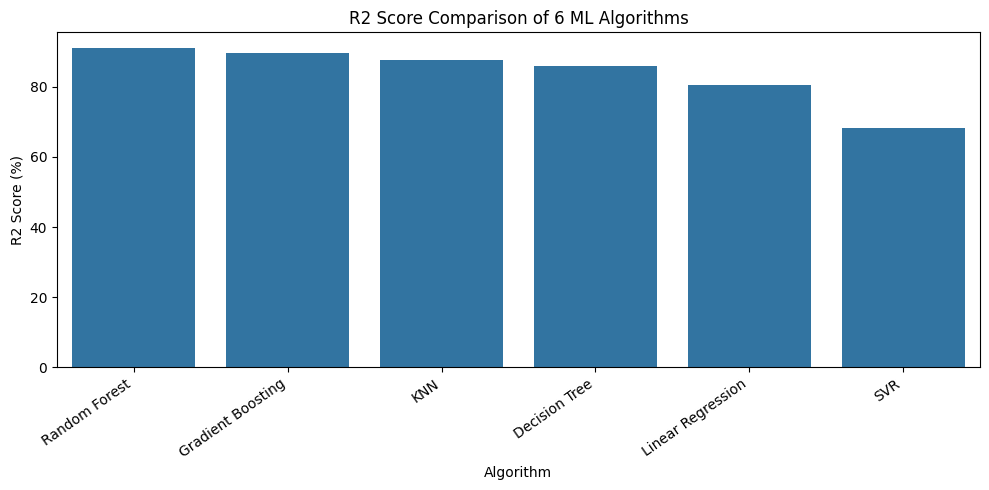

In [ ]:
# Compare R2 scores
plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x='Algorithm', y='R2 Score (%)')
plt.title('R2 Score Comparison of 6 ML Algorithms')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

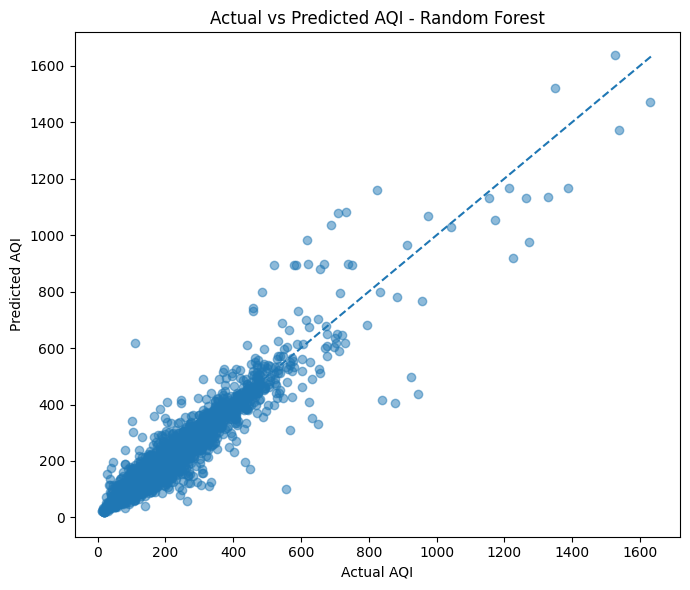

In [ ]:
best_model = trained_models[best_model_name]
best_predictions = predictions[best_model_name]

plt.figure(figsize=(7, 6))
plt.scatter(y_test, best_predictions, alpha=0.5)

low = min(y_test.min(), best_predictions.min())
high = max(y_test.max(), best_predictions.max())

plt.plot([low, high], [low, high], linestyle='--')

plt.xlabel('Actual AQI')
plt.ylabel('Predicted AQI')
plt.title(f'Actual vs Predicted AQI - {best_model_name}')
plt.tight_layout()
plt.show()


In [ ]:
new_data = pd.DataFrame([{
    'PM2.5': 80,
    'PM10': 120,
    'NO2': 30,
    'NH3': 15,
    'CO': 1.0,
    'SO2': 10,
    'O3': 40,
    'NOx': 35
}])

predicted_aqi = best_model.predict(new_data)[0]

print("Best Algorithm:", best_model_name)
print("Predicted AQI:", round(predicted_aqi, 2))


Best Algorithm: Random Forest
Predicted AQI: 168.81


,Feature,Importance
0,PM2.5,0.4943
4,CO,0.3976
1,PM10,0.0377
7,NOx,0.0210
6,O3,0.0173
5,SO2,0.0145
2,NO2,0.0133
3,NH3,0.0042


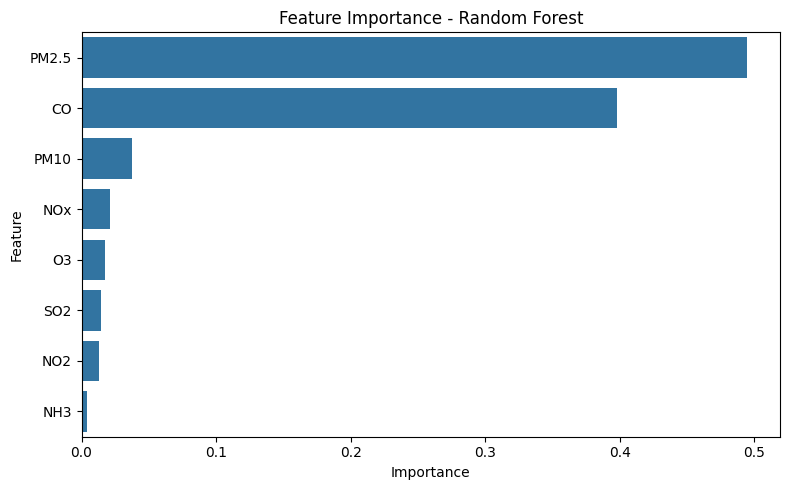

In [ ]:
rf_model = trained_models['Random Forest'].named_steps['model']

importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False)

display(importance_df.round(4))

plt.figure(figsize=(8, 5))
sns.barplot(data=importance_df, x='Importance', y='Feature')
plt.title('Feature Importance - Random Forest')
plt.tight_layout()
plt.show()


In [ ]:

best_result = results_df.iloc[0]

print("===== FINAL PROJECT REPORT =====")
print("Project: Air Quality Prediction")
print("Total Algorithms:", len(models))
print("Best Algorithm:", best_result['Algorithm'])
print("MAE:", round(best_result['MAE'], 3))
print("RMSE:", round(best_result['RMSE'], 3))
print("R2 Score:", round(best_result['R2 Score (%)'], 2), "%")


===== FINAL PROJECT REPORT =====
Project: Air Quality Prediction
Total Algorithms: 6
Best Algorithm: Random Forest
MAE: 21.031
RMSE: 40.525
R2 Score: 91.03 %


In [ ]:
def get_aqi_category(aqi):
    if aqi < 0:
        return "Invalid prediction"
    elif aqi <= 50:
        return "Good"
    elif aqi <= 100:
        return "Satisfactory"
    elif aqi <= 200:
        return "Moderate"
    elif aqi <= 300:
        return "Poor"
    elif aqi <= 400:
        return "Very Poor"
    elif aqi <= 500:
        return "Severe"
    else:
        return "Outside standard AQI range"

# Fallback to 'predicted_aqi' if 'prediction' variable from the interrupted cell doesn't exist
if 'prediction' in globals():
    final_prediction = prediction
elif 'predicted_aqi' in globals():
    final_prediction = predicted_aqi
else:
    final_prediction = None

if final_prediction is not None:
    print("Predicted AQI:", round(final_prediction, 2))
    print("AQI Category:", get_aqi_category(final_prediction))
else:
    print("Error: No prediction variable is available. Please run the model prediction step first.")

Predicted AQI: 168.81
AQI Category: Moderate


In [ ]:
results_df.to_csv('algorithm_comparison.csv', index=False)

print("Results saved successfully!")


Results saved successfully!


In [ ]:

from google.colab import files
files.download('algorithm_comparison.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Interactive dashboard

In [ ]:

import joblib

bundle = {
    "models": trained_models,
    "features": features,
    "results": results_df,
    "data": df
}

joblib.dump(bundle, "air_quality_project.pkl")

print("Project models and data saved successfully!")


Project models and data saved successfully!


In [ ]:

%%writefile app.py

import streamlit as st
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

st.set_page_config(
    page_title="Air Quality Prediction",
    page_icon="🌍",
    layout="wide"
)

# Load saved project
bundle = joblib.load("air_quality_project.pkl")

models = bundle["models"]
features = bundle["features"]
results = bundle["results"]
df = bundle["data"]

# AQI category
def get_aqi_category(aqi):
    if aqi < 0:
        return "Invalid prediction"
    elif aqi <= 50:
        return "Good"
    elif aqi <= 100:
        return "Satisfactory"
    elif aqi <= 200:
        return "Moderate"
    elif aqi <= 300:
        return "Poor"
    elif aqi <= 400:
        return "Very Poor"
    elif aqi <= 500:
        return "Severe"
    return "Outside standard AQI range"

# Header
st.title("🌍 Air Quality Prediction Dashboard")
st.write(
    "Machine Learning based AQI estimation "
    "using 8 air pollutant features and 6 algorithms."
)

st.info(
    "This project estimates AQI from pollutant values. "
    "It is a demonstration, not an official AQI monitoring service."
)

# Dataset overview
st.subheader("📊 Dataset Overview")

c1, c2, c3 = st.columns(3)
c1.metric("Total Records", f"{len(df):,}")
c2.metric("Input Features", len(features))
c3.metric("ML Algorithms", len(models))

with st.expander("View dataset sample"):
    st.dataframe(df.head(20), use_container_width=True)

# Prediction section
st.divider()
st.header("🔮 Predict Air Quality Index")

selected_model = st.selectbox(
    "Select Machine Learning Algorithm",
    list(models.keys())
)

st.write("Enter pollutant values below:")

# Defaults are illustrative examples, not live readings.
defaults = {
    "PM2.5": 80.0,
    "PM10": 120.0,
    "NO2": 30.0,
    "NH3": 15.0,
    "CO": 1.0,
    "SO2": 10.0,
    "O3": 40.0,
    "NOx": 35.0
}

with st.form("prediction_form"):
    cols = st.columns(2)
    values = {}

    for i, feature in enumerate(features):
        with cols[i % 2]:
            values[feature] = st.number_input(
                f"{feature}",
                min_value=0.0,
                value=defaults.get(feature, 0.0),
                step=1.0
            )

    submitted = st.form_submit_button(
        "Predict AQI",
        use_container_width=True
    )

if submitted:
    input_df = pd.DataFrame([values], columns=features)
    prediction = float(models[selected_model].predict(input_df)[0])
    category = get_aqi_category(prediction)

    st.subheader("Prediction Result")

    r1, r2, r3 = st.columns(3)
    r1.metric("Estimated AQI", f"{prediction:.2f}")
    r2.metric("AQI Category", category)
    r3.metric("Selected Model", selected_model)

    if 0 <= prediction <= 50:
        st.success("Estimated category: Good")
    elif prediction <= 100 and prediction >= 0:
        st.info("Estimated category: Satisfactory")
    elif prediction <= 200 and prediction >= 0:
        st.warning("Estimated category: Moderate")
    elif prediction <= 300 and prediction >= 0:
        st.warning("Estimated category: Poor")
    elif prediction <= 500 and prediction >= 0:
        st.error("Estimated category: Very Poor / Severe")
    else:
        st.warning(
            "Prediction is outside the standard 0–500 AQI range."
        )

    st.caption(
        "Use actual measured pollutant values for meaningful results. "
        "The estimate is not an official AQI reading."
    )

    st.subheader("Your Input Values")
    st.dataframe(input_df, use_container_width=True)

# Algorithm comparison
st.divider()
st.header("🏆 Algorithm Performance Comparison")

comparison = results.sort_values("RMSE").reset_index(drop=True)
st.dataframe(
    comparison.round(3),
    use_container_width=True,
    hide_index=True
)

st.subheader("RMSE Comparison")
chart_data = comparison.set_index("Algorithm")[["RMSE"]]
st.bar_chart(chart_data)

st.subheader("R² Score Comparison (%)")
r2_data = comparison.set_index("Algorithm")[["R2 Score (%)"]]
st.bar_chart(r2_data)

best = comparison.iloc[0]
st.success(
    f"Lowest RMSE in this test split: {best['Algorithm']} "
    f"(RMSE: {best['RMSE']:.2f})"
)

# Historical data charts
st.divider()
st.header("📈 Air Quality Data Analysis")

if "AQI" in df.columns:
    chart_df = df[["AQI"]].dropna()
    st.subheader("AQI Distribution")
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.hist(chart_df["AQI"], bins=30)
    ax.set_xlabel("AQI")
    ax.set_ylabel("Number of records")
    ax.set_title("Distribution of AQI in Dataset")
    st.pyplot(fig)
    plt.close(fig)

if "City" in df.columns and "AQI" in df.columns:
    city_aqi = (
        df.groupby("City")["AQI"]
        .mean()
        .dropna()
        .sort_values(ascending=False)
        .head(10)
    )

    st.subheader("10 Cities with Highest Average AQI")
    st.bar_chart(city_aqi)

st.caption(
    "Educational ML project | Predictions depend on the "
    "dataset and trained models. No live sensor data is connected."
)


Writing app.py


In [ ]:

!pip -q install streamlit joblib


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 77.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 93.6 MB/s eta 0:00:00


In [ ]:
!streamlit run app.py --server.port 8501 --server.address 0.0.0.0 > streamlit.log 2>&1 &


In [ ]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64.deb -O cloudflared.deb
!dpkg -i cloudflared.deb


Selecting previously unselected package cloudflared.
(Reading database ... 122807 files and directories currently installed.)
Preparing to unpack cloudflared.deb ...
Unpacking cloudflared (2026.10.3) ...
Setting up cloudflared (2026.10.3) ...
Processing triggers for man-db (2.12.0-4build2) ...


In [ ]:
!cloudflared tunnel --url http://localhost:8501


2026-10-23T07:26:01Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-10-23T07:26:01Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-10-23T07:26:05Z INF +--------------------------------------------------------------------------------------------+
2026-10-23T07:26:05Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-10-23T07:26:05Z INF |  https://lightbox-cartoons-surveillance-cabinet.tryclo